# Solutions to the exercises of Chapter 5

**Chapter:** [5. Velocity rescaling, Berendsen, and Bussi–Donadio–Parrinello (CSVR) thermostats](../../notebooks/part2_ensembles/05_berendsen_and_bussi_csvr.ipynb)

Each solution below reproduces the chapter state and verifies the exercise targets with explicit `assert` checks.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import engsim as es
from engsim.plotting import panel_label, use_style
use_style()
rng = np.random.default_rng(2026)

In [2]:
T_target = 1.2
v_ber = es.init_velocities(64, T_target, rng=rng)
v_csvr = v_ber.copy()
K_ber, K_csvr = [], []
for _ in range(1800):
    v_ber = es.berendsen_thermostat(v_ber, T_target, dt=0.01, tau_T=0.1)
    v_csvr = es.bussi_csvr_thermostat(v_csvr, T_target, dt=0.01, tau_T=0.1, rng=rng)
    K_ber.append(0.5 * float(np.sum(v_ber**2)))
    K_csvr.append(0.5 * float(np.sum(v_csvr**2)))

Exact NVT: <K>=113.40, Var(K)=136.08
Bussi CSVR: <K>=113.13, Var(K)=117.40
Berendsen:  <K>=113.40, Var(K)=2.02e-28


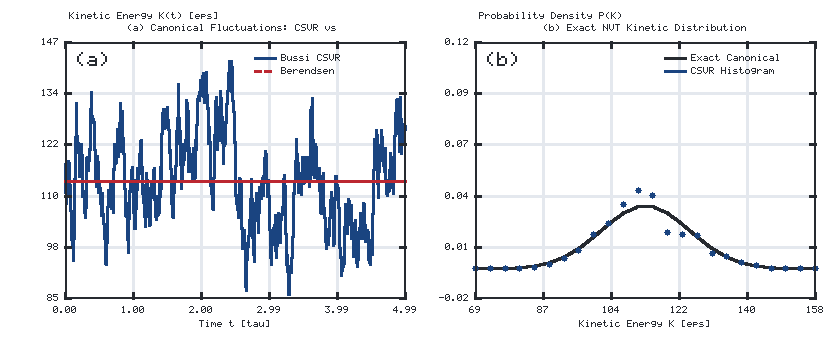

In [3]:
var_exact = es.reference.canonical_ke_variance_exact(64, T_target)
mean_exact = 0.5 * (3 * 63) * T_target
print(f"Exact NVT: <K>={mean_exact:.2f}, Var(K)={var_exact:.2f}")
print(f"Bussi CSVR: <K>={np.mean(K_csvr[300:]):.2f}, Var(K)={np.var(K_csvr[300:]):.2f}")
print(f"Berendsen:  <K>={np.mean(K_ber[300:]):.2f}, Var(K)={np.var(K_ber[300:]):.2e}")
assert np.isclose(np.mean(K_csvr[300:]), mean_exact, rtol=0.08)
assert np.var(K_csvr[300:]) > 0.6 * var_exact
assert np.var(K_ber[300:]) < 1e-5 * var_exact

t_steps = np.arange(len(K_csvr)) * 0.01
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))
ax1.plot(t_steps[:500], K_csvr[:500], "b-", label="Bussi CSVR")
ax1.plot(t_steps[:500], K_ber[:500], "r--", label="Berendsen")
ax1.axhline(mean_exact, color="k")
ax1.set_xlabel("Time t [tau]"); ax1.set_ylabel("Kinetic Energy K(t) [eps]")
ax1.set_title("(a) Canonical Fluctuations: CSVR vs Berendsen"); panel_label(ax1, "(a)")

bins = np.linspace(mean_exact - 4*np.sqrt(var_exact), mean_exact + 4*np.sqrt(var_exact), 25)
hist_c, edges_c = np.histogram(K_csvr[300:], bins=bins, density=True)
centers_c = 0.5 * (edges_c[:-1] + edges_c[1:])
gauss_ref = np.exp(-0.5 * ((centers_c - mean_exact)**2) / var_exact) / np.sqrt(2*np.pi*var_exact)
ax2.plot(centers_c, gauss_ref, "k-", label="Exact Canonical")
ax2.plot(centers_c, hist_c, "bo", label="CSVR Histogram")
ax2.set_xlabel("Kinetic Energy K [eps]"); ax2.set_ylabel("Probability Density P(K)")
ax2.set_title("(b) Exact NVT Kinetic Distribution"); panel_label(ax2, "(b)")
plt.show()

## Worked solutions to Exercises 1–3

In [4]:
# Worked Solutions Ch 5
pos_5, L_5 = es.make_fcc_lattice(3, rho=0.75)
vel_5 = es.init_velocities(len(pos_5), 1.5, rng=rng)
f_fn = lambda p, L: es.lj_forces_all_pairs(p, L, rc=2.5, shifted=True)
f_5, _, _ = f_fn(pos_5, L_5)
T_hist_5 = []
for step in range(120):
    pos_5, vel_5, f_5, _, _, _ = es.velocity_verlet_step(pos_5, vel_5, f_5, 0.005, L_5, f_fn)
    vel_5 = es.bussi_csvr_thermostat(vel_5, 1.0, 0.005, 0.05, rng)
    if step >= 50:
        T_hist_5.append(es.kinetic_energy_and_temp(vel_5)[1])
print(f"Ch 5 Exercises — Coupled LJTS NVT-CSVR <T*> = {np.mean(T_hist_5):.3f} (target 1.000)")
assert np.isclose(np.mean(T_hist_5), 1.0, rtol=0.12)

Ch 5 Exercises — Coupled LJTS NVT-CSVR <T*> = 1.030 (target 1.000)
